# Comparaison des Modèles

Ce notebook compare les performances de tous les modèles de Machine Learning pour identifier le meilleur candidat pour prédire l'attrition des employés.

## 1. Importation des bibliothèques

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_score, recall_score, f1_score, accuracy_score,
    roc_curve, roc_auc_score, precision_recall_curve
)
import pickle
import time

## 2. Chargement des données et des modèles

In [2]:
# Charger les données préparées
data = pd.read_csv('Data/prepared_data.csv')

# Séparer les caractéristiques et la cible
X = data.drop(columns=["Attrition", "EmployeeID"])
y = data['Attrition']

# Séparation train/test (70/30)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(f"Données chargées avec succès!")
print(f"Taille ensemble de test: {X_test.shape[0]}")

Données chargées avec succès!
Taille ensemble de test: 1323


In [3]:
# Charger tous les modèles
models = {}
model_files = [
    'logistic_regression_model.pkl',
    'perceptron_model.pkl',
    'svm_model.pkl',
    'naive_bayes_model.pkl',
    'decision_tree_model.pkl',
    'random_forest_model.pkl',
    'knn_model.pkl'
]

model_names = [
    'Logistic Regression',
    'Perceptron',
    'SVM',
    'Naive Bayes',
    'Decision Tree',
    'Random Forest',
    'k-NN'
]

for name, file in zip(model_names, model_files):
    try:
        with open(f'Data/{file}', 'rb') as f:
            models[name] = pickle.load(f)
        print(f"✓ {name} chargé")
    except FileNotFoundError:
        print(f"✗ {name} non trouvé - veuillez exécuter le notebook correspondant")

✓ Logistic Regression chargé
✓ Perceptron chargé
✓ SVM chargé
✓ Naive Bayes chargé
✓ Decision Tree chargé
✓ Random Forest chargé
✓ k-NN chargé


## 3. Génération des prédictions

In [4]:
# Générer les prédictions pour tous les modèles
predictions = {}
probabilities = {}

for name, model in models.items():
    predictions[name] = model.predict(X_test)
    if hasattr(model, "predict_proba"):
        probabilities[name] = model.predict_proba(X_test)[:, 1]
    else:
        probabilities[name] = predictions[name]  # Pour Perceptron

print("Prédictions générées pour tous les modèles!")

Prédictions générées pour tous les modèles!


## 4. Calcul des métriques de performance

In [5]:
# Calculer toutes les métriques
metrics_data = []

for name in models.keys():
    y_pred = predictions[name]
    y_proba = probabilities[name]
    
    metrics_data.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred),
        'AUC-ROC': roc_auc_score(y_test, y_proba) if len(np.unique(y_proba)) > 1 else roc_auc_score(y_test, y_pred)
    })

# Créer un DataFrame avec les métriques
metrics_df = pd.DataFrame(metrics_data)
metrics_df = metrics_df.round(4)

print("\n=== MÉTRIQUES DE PERFORMANCE ===")
print(metrics_df.to_string(index=False))

# Sauvegarder les métriques
metrics_df.to_csv('Data/model_comparison_metrics.csv', index=False)
print("\nMétriques sauvegardées dans Data/model_comparison_metrics.csv")


=== MÉTRIQUES DE PERFORMANCE ===
              Model  Accuracy  Precision  Recall  F1 Score  AUC-ROC
Logistic Regression    0.8587     0.6082  0.2837    0.3869   0.8024
         Perceptron    0.8186     0.4048  0.3269    0.3617   0.6186
                SVM    0.9123     0.9340  0.4760    0.6306   0.9225
        Naive Bayes    0.8027     0.3853  0.4279    0.4055   0.7398
      Decision Tree    0.9705     0.9163  0.8942    0.9051   0.9395
      Random Forest    0.9834     1.0000  0.8942    0.9442   0.9949
               k-NN    0.8284     0.4354  0.3077    0.3606   0.8383

Métriques sauvegardées dans Data/model_comparison_metrics.csv


## 5. Visualisation comparative des métriques

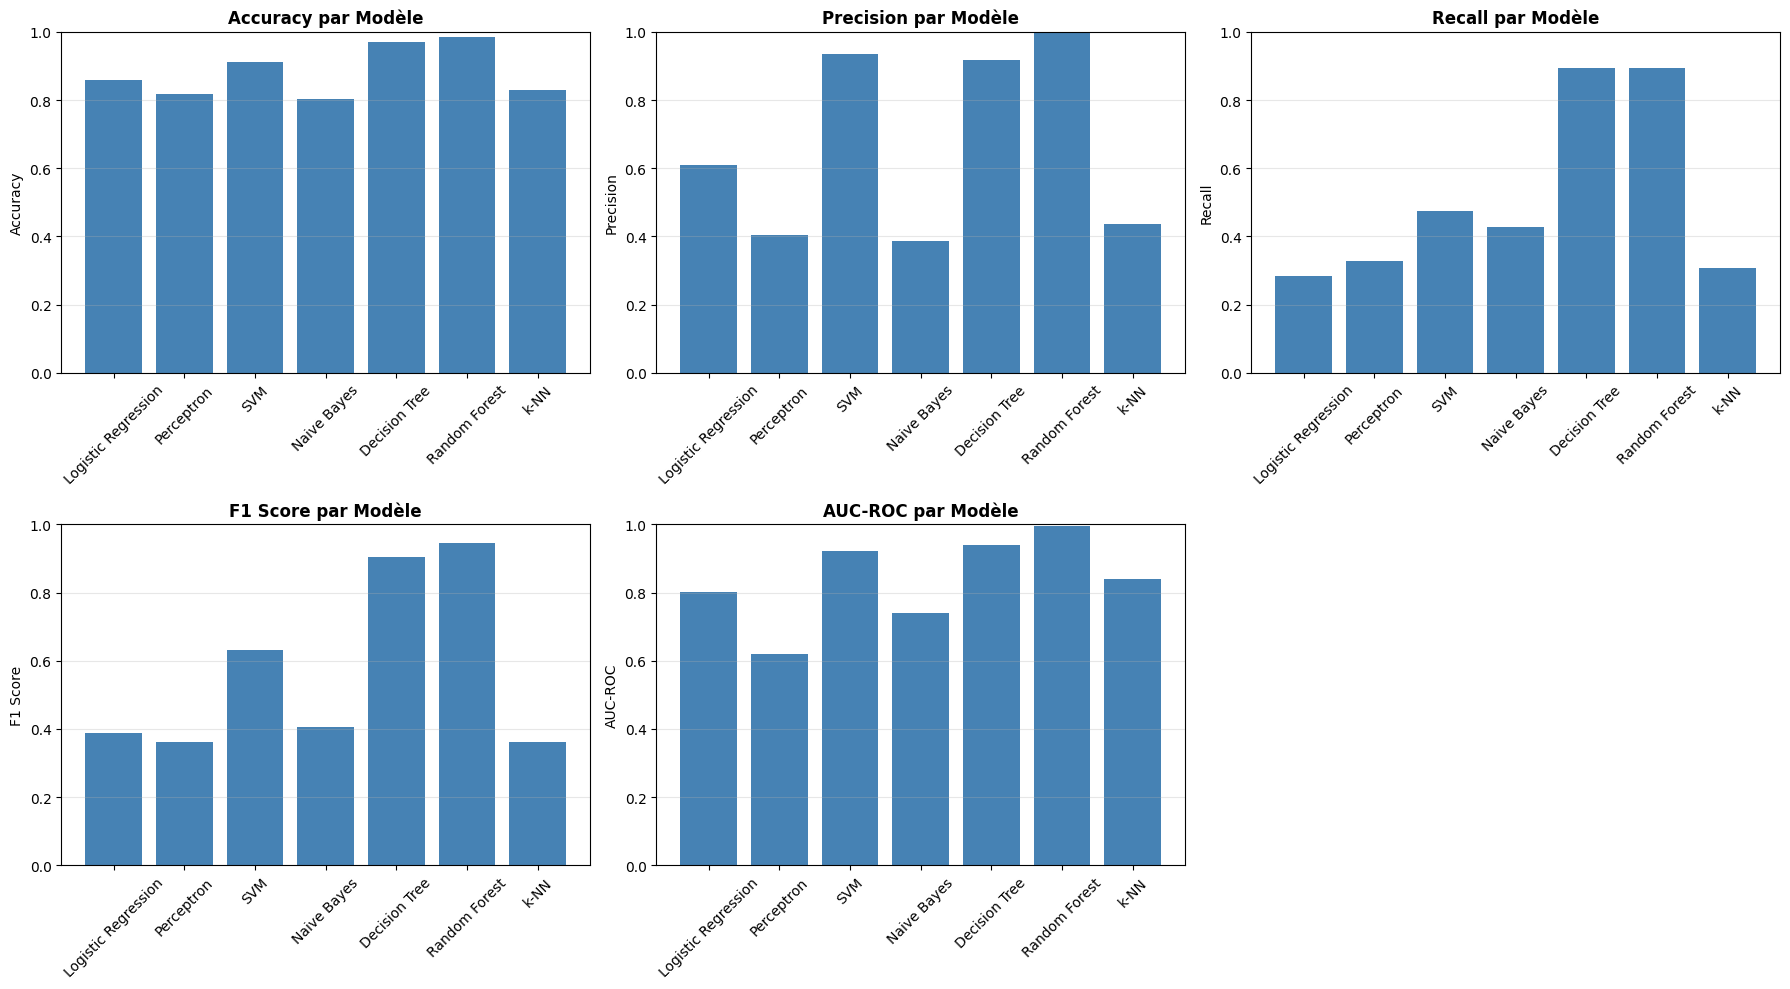

In [6]:
# Graphique en barres pour toutes les métriques
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'AUC-ROC']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

for idx, metric in enumerate(metrics_to_plot):
    axes[idx].bar(metrics_df['Model'], metrics_df[metric], color='steelblue')
    axes[idx].set_title(f'{metric} par Modèle', fontsize=12, fontweight='bold')
    axes[idx].set_ylabel(metric)
    axes[idx].set_ylim([0, 1])
    axes[idx].tick_params(axis='x', rotation=45)
    axes[idx].grid(axis='y', alpha=0.3)

# Supprimer le dernier subplot vide
fig.delaxes(axes[5])

plt.tight_layout()
plt.savefig('Data/model_comparison_bars.png', dpi=300, bbox_inches='tight')
plt.show()

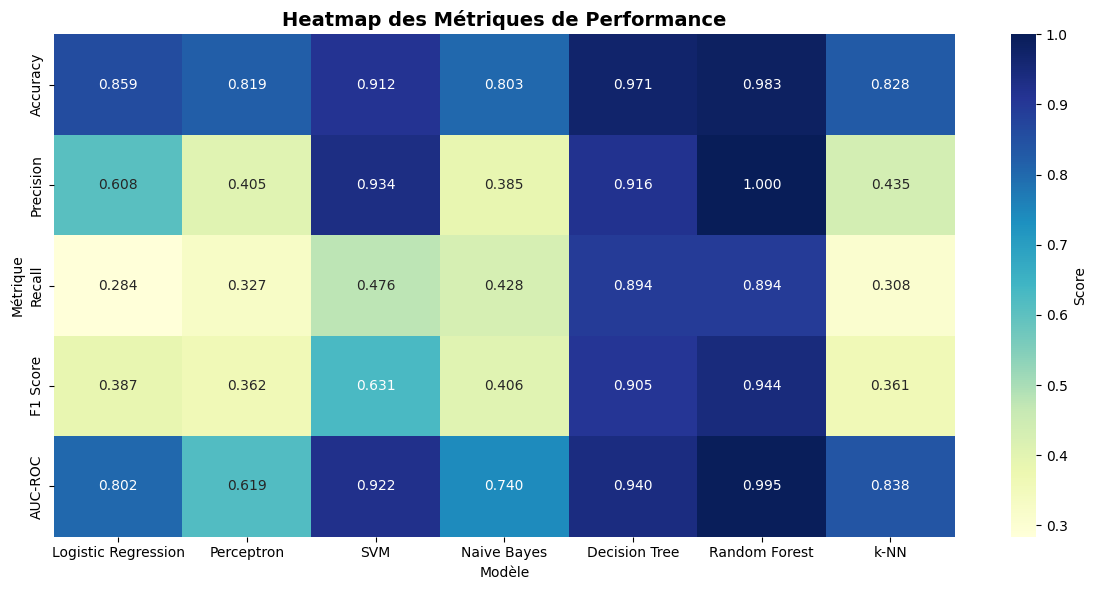

In [7]:
# Heatmap des métriques
plt.figure(figsize=(12, 6))
metrics_for_heatmap = metrics_df.set_index('Model')[metrics_to_plot].T
sns.heatmap(metrics_for_heatmap, annot=True, fmt='.3f', cmap='YlGnBu', cbar_kws={'label': 'Score'})
plt.title('Heatmap des Métriques de Performance', fontsize=14, fontweight='bold')
plt.ylabel('Métrique')
plt.xlabel('Modèle')
plt.tight_layout()
plt.savefig('Data/model_comparison_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

## 6. Comparaison des courbes ROC

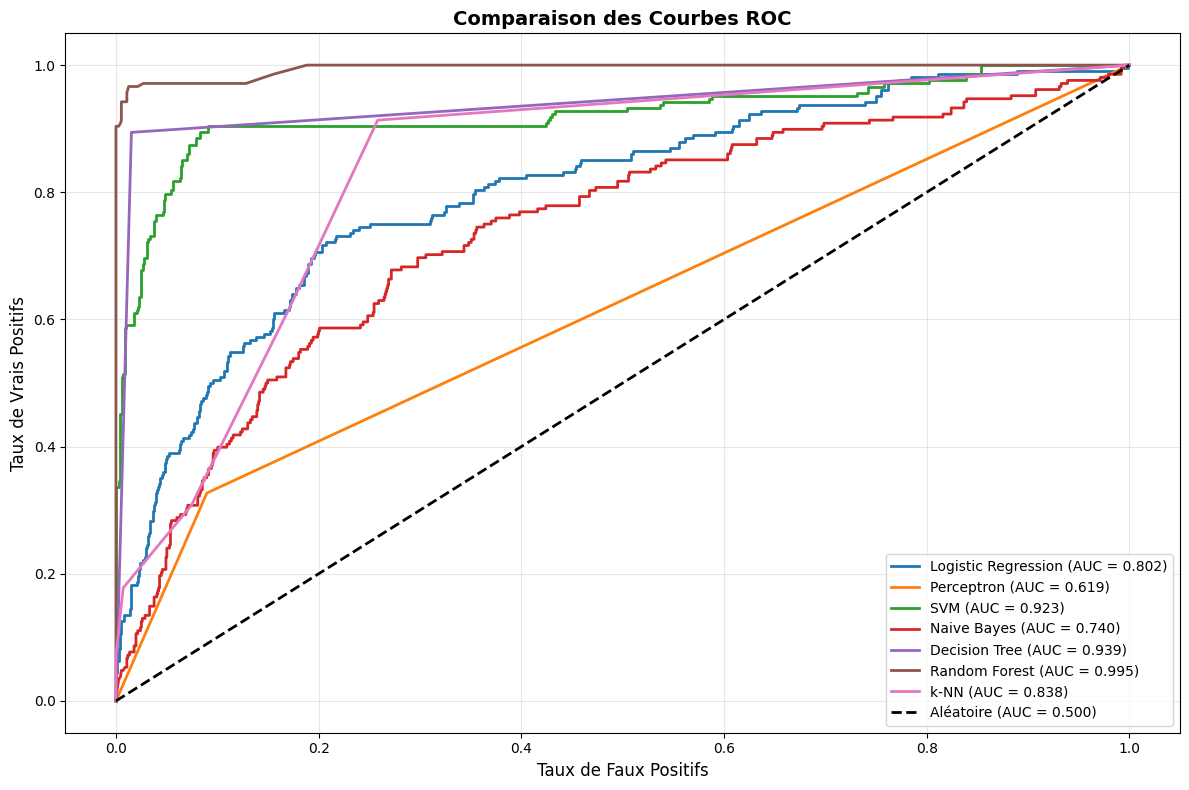

In [8]:
# Tracer toutes les courbes ROC sur un seul graphique
plt.figure(figsize=(12, 8))

for name in models.keys():
    y_proba = probabilities[name]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba) if len(np.unique(y_proba)) > 1 else roc_auc_score(y_test, predictions[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})", linewidth=2)

plt.plot([0, 1], [0, 1], 'k--', label='Aléatoire (AUC = 0.500)', linewidth=2)
plt.xlabel('Taux de Faux Positifs', fontsize=12)
plt.ylabel('Taux de Vrais Positifs', fontsize=12)
plt.title('Comparaison des Courbes ROC', fontsize=14, fontweight='bold')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('Data/model_comparison_roc.png', dpi=300, bbox_inches='tight')
plt.show()

## 7. Comparaison des courbes Précision-Rappel

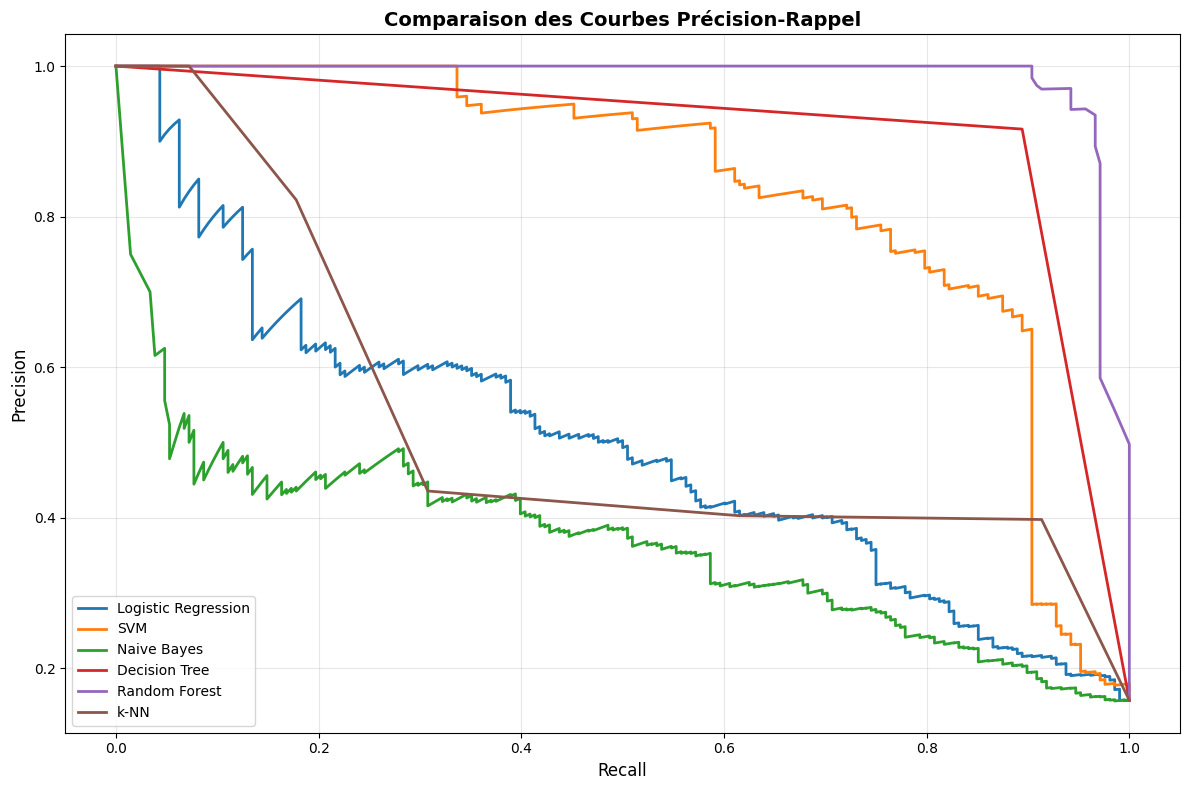

In [9]:
# Tracer toutes les courbes Précision-Rappel
plt.figure(figsize=(12, 8))

for name in models.keys():
    if hasattr(models[name], "predict_proba"):
        y_proba = probabilities[name]
        precision, recall, _ = precision_recall_curve(y_test, y_proba)
        plt.plot(recall, precision, label=name, linewidth=2)

plt.xlabel('Recall', fontsize=12)
plt.ylabel('Precision', fontsize=12)
plt.title('Comparaison des Courbes Précision-Rappel', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('Data/model_comparison_pr.png', dpi=300, bbox_inches='tight')
plt.show()

## 8. Comparaison des matrices de confusion

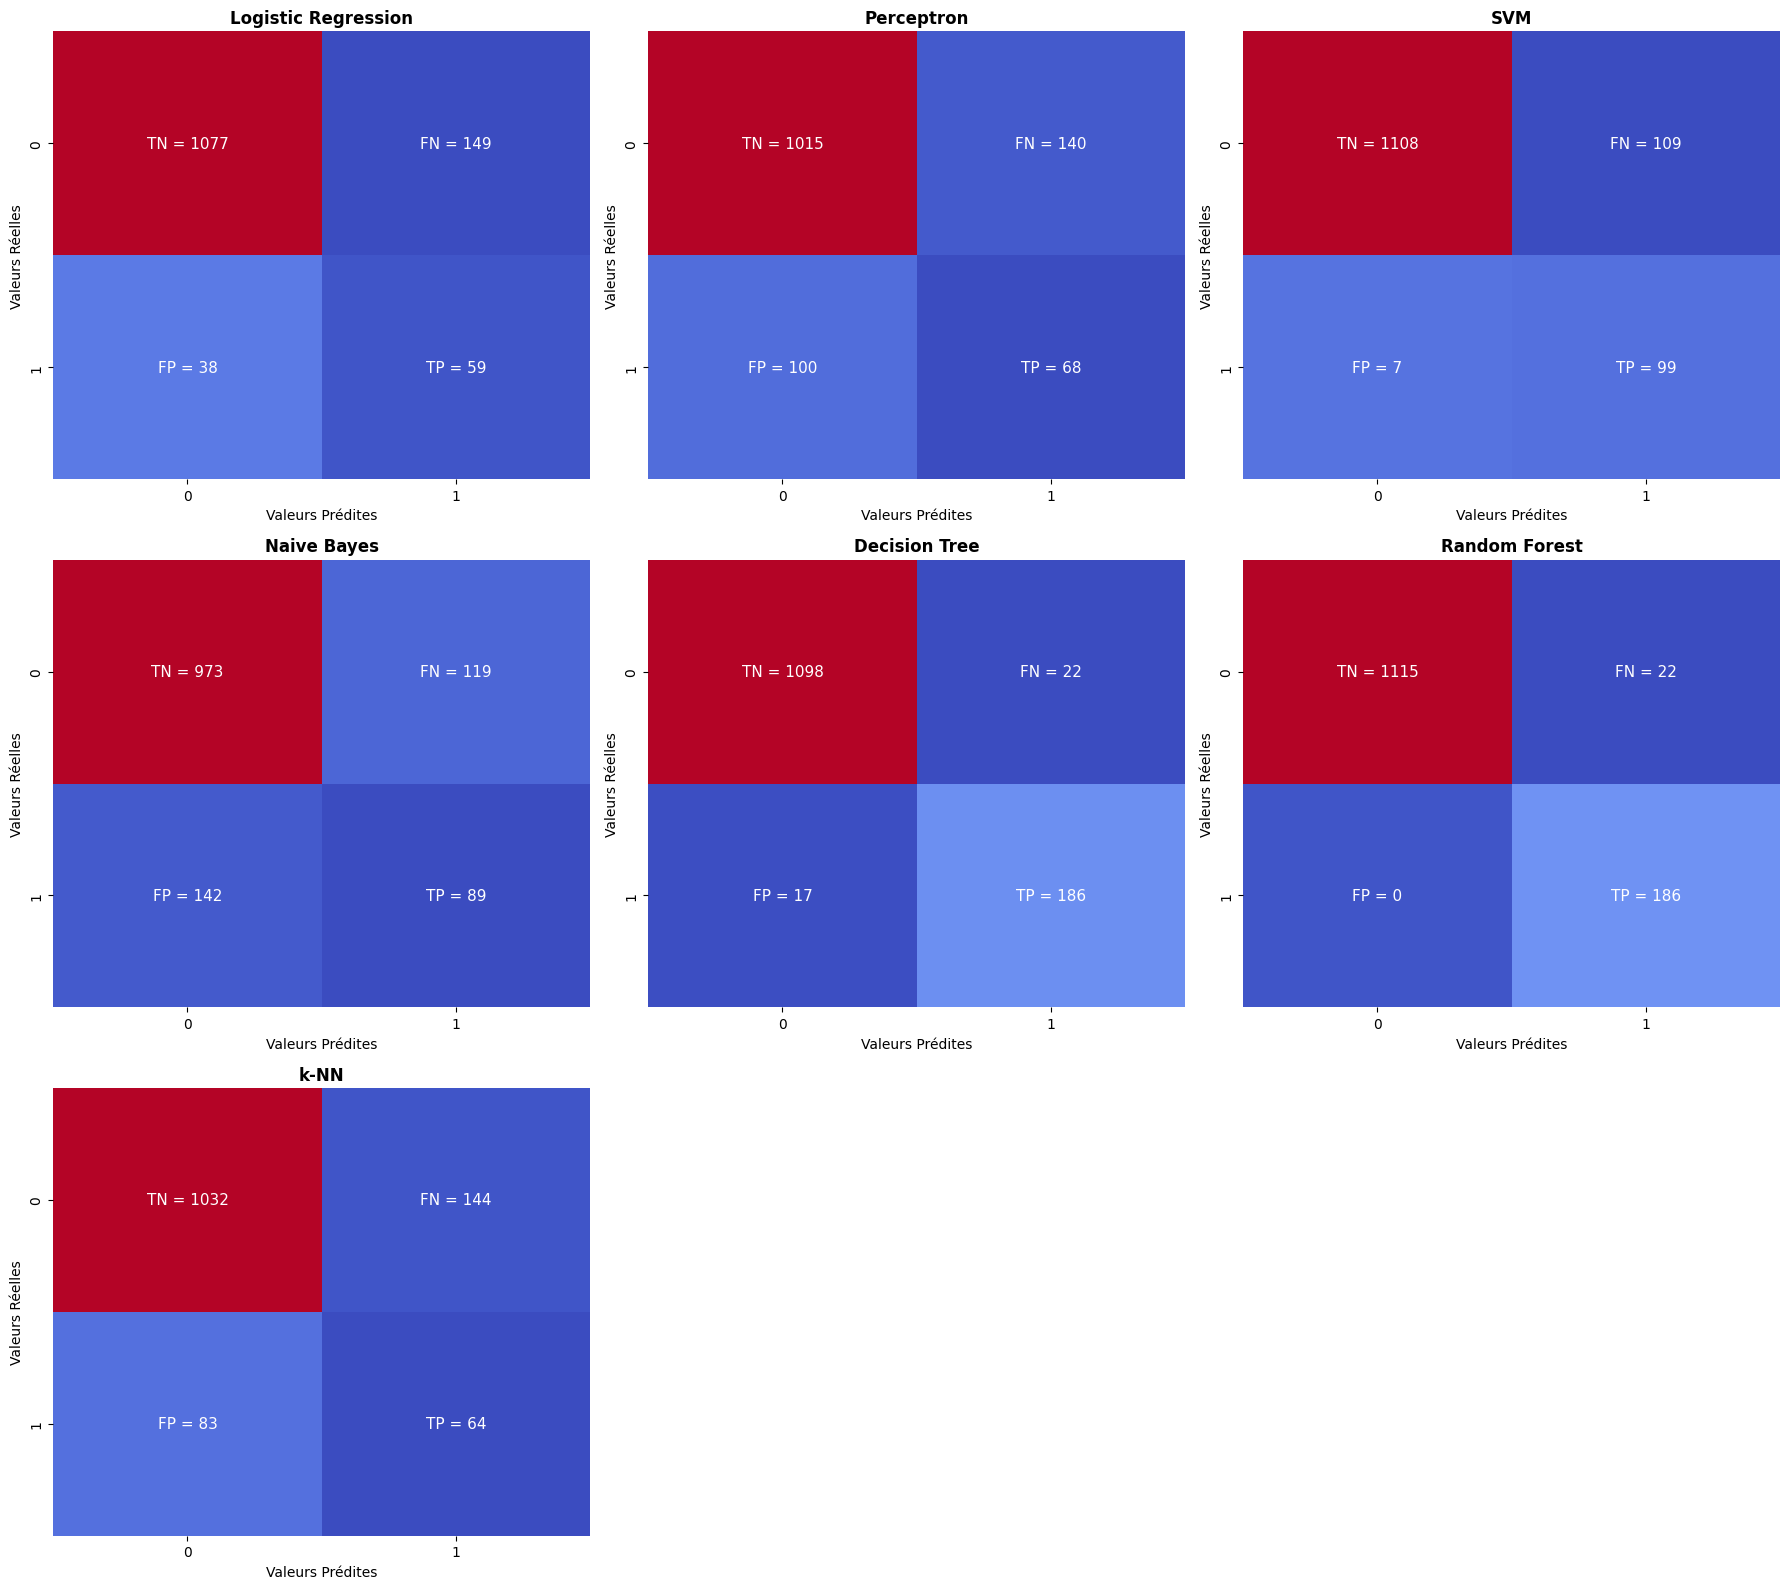

In [10]:
from sklearn.metrics import confusion_matrix

# Créer un subplot pour toutes les matrices de confusion
fig, axes = plt.subplots(3, 3, figsize=(18, 16))
axes = axes.ravel()

for idx, name in enumerate(models.keys()):
    y_pred = predictions[name]
    conf_matrix = confusion_matrix(y_test, y_pred)
    
    sns.heatmap(conf_matrix, annot=False, fmt="d", cmap="coolwarm", 
                cbar=False, ax=axes[idx])
    
    # Ajouter les valeurs TP, TN, FP, FN
    TN, FP, FN, TP = conf_matrix.ravel()
    axes[idx].text(0.5, 0.5, f'TN = {TN}', ha='center', va='center', color='white', fontsize=11)
    axes[idx].text(0.5, 1.5, f'FP = {FP}', ha='center', va='center', color='white', fontsize=11)
    axes[idx].text(1.5, 0.5, f'FN = {FN}', ha='center', va='center', color='white', fontsize=11)
    axes[idx].text(1.5, 1.5, f'TP = {TP}', ha='center', va='center', color='white', fontsize=11)
    
    axes[idx].set_title(name, fontsize=12, fontweight='bold')
    axes[idx].set_ylabel('Valeurs Réelles')
    axes[idx].set_xlabel('Valeurs Prédites')

# Supprimer les subplots vides
for idx in range(len(models), 9):
    fig.delaxes(axes[idx])

plt.tight_layout()
plt.savefig('Data/model_comparison_confusion_matrices.png', dpi=300, bbox_inches='tight')
plt.show()

## 9. Mesure du temps d'exécution

In [11]:
# Mesurer le temps d'entraînement et de prédiction
time_data = []

for name, model in models.items():
    # Temps d'entraînement
    start_time = time.time()
    model.fit(X_train, y_train)
    training_time = time.time() - start_time
    
    # Temps de prédiction
    start_time = time.time()
    model.predict(X_test)
    prediction_time = time.time() - start_time
    
    time_data.append({
        'Model': name,
        'Training Time (s)': round(training_time, 4),
        'Prediction Time (s)': round(prediction_time, 4),
        'Total Time (s)': round(training_time + prediction_time, 4)
    })

# Créer un DataFrame
time_df = pd.DataFrame(time_data)

print("\n=== TEMPS D'EXÉCUTION ===")
print(time_df.to_string(index=False))

# Sauvegarder
time_df.to_csv('Data/model_comparison_times.csv', index=False)


=== TEMPS D'EXÉCUTION ===
              Model  Training Time (s)  Prediction Time (s)  Total Time (s)
Logistic Regression             0.0193               0.0010          0.0203
         Perceptron             0.0045               0.0000          0.0045
                SVM             0.6270               0.0904          0.7173
        Naive Bayes             0.0032               0.0010          0.0042
      Decision Tree             0.0177               0.0010          0.0187
      Random Forest             0.2621               0.0182          0.2803
               k-NN             0.0000               0.0664          0.0664


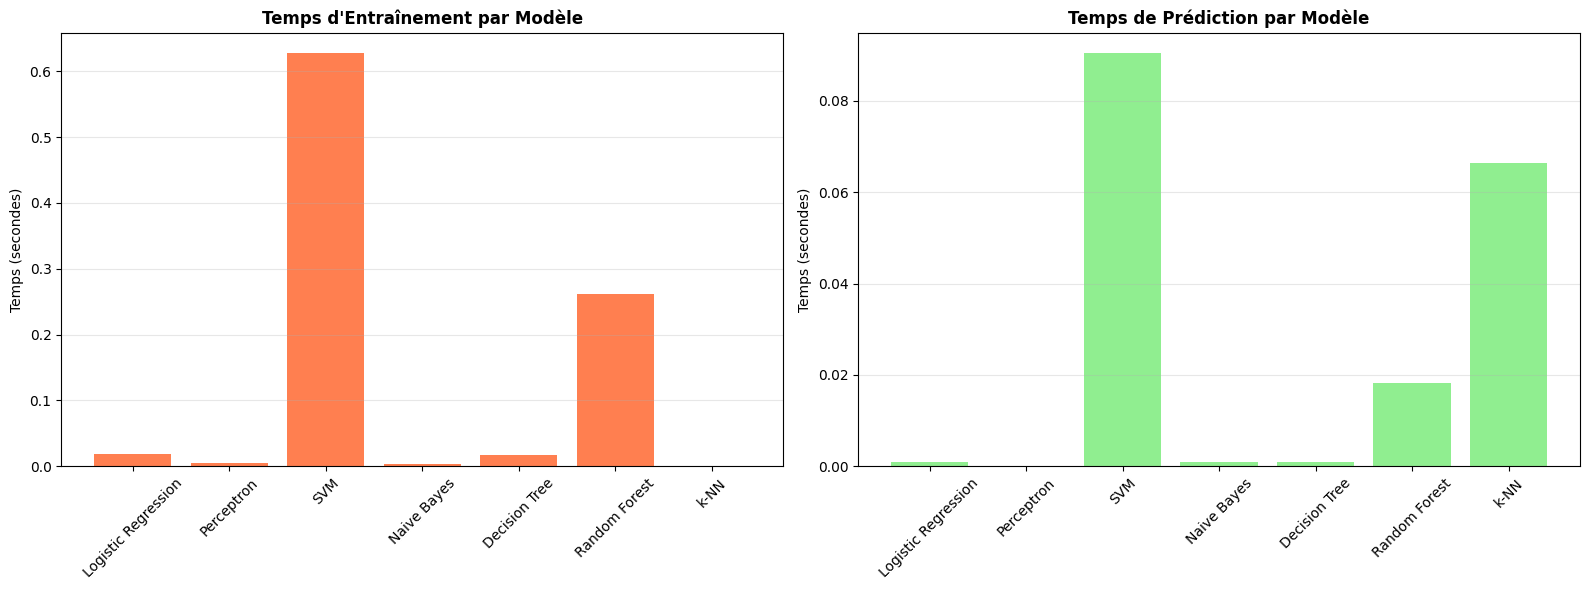

In [12]:
# Visualisation des temps d'exécution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Temps d'entraînement
ax1.bar(time_df['Model'], time_df['Training Time (s)'], color='coral')
ax1.set_title('Temps d\'Entraînement par Modèle', fontsize=12, fontweight='bold')
ax1.set_ylabel('Temps (secondes)')
ax1.tick_params(axis='x', rotation=45)
ax1.grid(axis='y', alpha=0.3)

# Temps de prédiction
ax2.bar(time_df['Model'], time_df['Prediction Time (s)'], color='lightgreen')
ax2.set_title('Temps de Prédiction par Modèle', fontsize=12, fontweight='bold')
ax2.set_ylabel('Temps (secondes)')
ax2.tick_params(axis='x', rotation=45)
ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('Data/model_comparison_times.png', dpi=300, bbox_inches='tight')
plt.show()

## 10. Identification du meilleur modèle

In [13]:
# Déterminer le meilleur modèle selon différents critères
print("\n=== MEILLEURS MODÈLES PAR CRITÈRE ===")
print(f"\nMeilleure Accuracy    : {metrics_df.loc[metrics_df['Accuracy'].idxmax(), 'Model']} ({metrics_df['Accuracy'].max():.4f})")
print(f"Meilleure Precision   : {metrics_df.loc[metrics_df['Precision'].idxmax(), 'Model']} ({metrics_df['Precision'].max():.4f})")
print(f"Meilleur Recall       : {metrics_df.loc[metrics_df['Recall'].idxmax(), 'Model']} ({metrics_df['Recall'].max():.4f})")
print(f"Meilleur F1 Score     : {metrics_df.loc[metrics_df['F1 Score'].idxmax(), 'Model']} ({metrics_df['F1 Score'].max():.4f})")
print(f"Meilleur AUC-ROC      : {metrics_df.loc[metrics_df['AUC-ROC'].idxmax(), 'Model']} ({metrics_df['AUC-ROC'].max():.4f})")

# Modèle le plus rapide
print(f"\nModèle le plus rapide : {time_df.loc[time_df['Total Time (s)'].idxmin(), 'Model']} ({time_df['Total Time (s)'].min():.4f}s)")

# Score global (moyenne des métriques normalisées)
metrics_normalized = metrics_df.copy()
for col in metrics_to_plot:
    metrics_normalized[col] = (metrics_normalized[col] - metrics_normalized[col].min()) / (metrics_normalized[col].max() - metrics_normalized[col].min())

metrics_normalized['Global Score'] = metrics_normalized[metrics_to_plot].mean(axis=1)
best_overall_idx = metrics_normalized['Global Score'].idxmax()

print(f"\n{'='*50}")
print(f"🏆 MEILLEUR MODÈLE GLOBAL : {metrics_df.loc[best_overall_idx, 'Model']}")
print(f"{'='*50}")
print(f"\nScore global : {metrics_normalized.loc[best_overall_idx, 'Global Score']:.4f}")
print(f"\nMétriques :")
for metric in metrics_to_plot:
    print(f"  - {metric:12s}: {metrics_df.loc[best_overall_idx, metric]:.4f}")


=== MEILLEURS MODÈLES PAR CRITÈRE ===

Meilleure Accuracy    : Random Forest (0.9834)
Meilleure Precision   : Random Forest (1.0000)
Meilleur Recall       : Decision Tree (0.8942)
Meilleur F1 Score     : Random Forest (0.9442)
Meilleur AUC-ROC      : Random Forest (0.9949)

Modèle le plus rapide : Naive Bayes (0.0042s)

🏆 MEILLEUR MODÈLE GLOBAL : Random Forest

Score global : 1.0000

Métriques :
  - Accuracy    : 0.9834
  - Precision   : 1.0000
  - Recall      : 0.8942
  - F1 Score    : 0.9442
  - AUC-ROC     : 0.9949


## 11. Sauvegarde du résumé comparatif

In [14]:
# Créer un rapport complet
comparison_summary = {
    'metrics': metrics_df,
    'times': time_df,
    'best_model': metrics_df.loc[best_overall_idx, 'Model'],
    'best_model_metrics': metrics_df.loc[best_overall_idx].to_dict()
}

with open('Data/model_comparison_summary.pkl', 'wb') as f:
    pickle.dump(comparison_summary, f)

print("\nRésumé comparatif sauvegardé dans Data/model_comparison_summary.pkl")


Résumé comparatif sauvegardé dans Data/model_comparison_summary.pkl


## Résumé

Ce notebook a permis de :
1. Charger tous les modèles entraînés
2. Générer des prédictions pour chaque modèle
3. Calculer et comparer toutes les métriques de performance
4. Visualiser les comparaisons (courbes ROC, Précision-Rappel, matrices de confusion)
5. Mesurer les temps d'exécution
6. Identifier le meilleur modèle selon différents critères
7. Sauvegarder tous les résultats pour utilisation dans le notebook d'optimisation